# 🧠 Notebook 04: Feature Engineering, Model Training & SHAP Explainability

**Project:** Customer Churn & Lifetime Value (LTV) Engine  
**Author:** Adarsh Kumar Pandey (*Machine Learning Engineer & Data Analyst*)  
**Dataset:** `data/telco_customer_churn_clean.csv`  
**Algorithms:** Logistic Regression, Random Forest, XGBoost  
**Objective:** Engineer predictive features, train classifiers with 5-fold cross-validation, evaluate ROC-AUC/Recall benchmarks, and interpret predictions using SHAP TreeExplainer.

## 1. Setup, Libraries & Clean Dataset Ingestion

In [1]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score, roc_curve, confusion_matrix
)
import shap

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120
%matplotlib inline

df = pd.read_csv('../data/telco_customer_churn_clean.csv')
print(f'Clean Dataset Ingested: {df.shape[0]} rows, {df.shape[1]} columns')
df.head()

Clean Dataset Ingested: 7043 rows, 21 columns


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 2. Advanced Feature Engineering
Creating domain-informed features based on exploratory discoveries:
- **Tenure cohorts** (lifecycle bucketing)
- **Total add-on services** & cybersecurity bundles
- **Financial ratios** (spend velocity and charge ratios)
- **Risk indicators** (Month-to-month, Fiber Optic, Electronic Check, High Spend)

In [2]:
# 1. Tenure Cohorts
bins = [-1, 12, 24, 36, 48, 60, 72]
labels = ['0-12m', '13-24m', '25-36m', '37-48m', '49-60m', '61-72m']
df['tenure_cohort'] = pd.cut(df['tenure'], bins=bins, labels=labels)

# 2. Service Counts & Bundles
service_cols = ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies']
for col in service_cols:
    df[f'{col}_flag'] = (df[col] == 'Yes').astype(int)

df['total_addon_services'] = df[[f'{col}_flag' for col in service_cols]].sum(axis=1)
df['security_bundle'] = ((df['OnlineSecurity'] == 'Yes') & (df['TechSupport'] == 'Yes')).astype(int)
df['streaming_bundle'] = ((df['StreamingTV'] == 'Yes') & (df['StreamingMovies'] == 'Yes')).astype(int)

# 3. Financial Ratios
df['charge_ratio'] = df['TotalCharges'] / (df['tenure'] + 1.0)
df['monthly_to_total_ratio'] = df['MonthlyCharges'] / (df['TotalCharges'] + 1.0)
df['has_family'] = ((df['Partner'] == 'Yes') | (df['Dependents'] == 'Yes')).astype(int)

# 4. High-Risk Binary Indicators
df['is_month_to_month'] = (df['Contract'] == 'Month-to-month').astype(int)
df['is_fiber_optic'] = (df['InternetService'] == 'Fiber optic').astype(int)
df['is_electronic_check'] = (df['PaymentMethod'] == 'Electronic check').astype(int)
df['high_monthly_charges'] = (df['MonthlyCharges'] >= 70.0).astype(int)

# Prepare features and target
drop_cols = ['customerID'] + [f'{col}_flag' for col in service_cols]
df_ml = df.drop(columns=drop_cols)

y = (df_ml['Churn'] == 'Yes').astype(int)
X = df_ml.drop(columns=['Churn'])

# One-Hot Encoding
cat_cols = X.select_dtypes(include=['object', 'category', 'string']).columns.tolist()
X_encoded = pd.get_dummies(X, columns=cat_cols, drop_first=True)
feature_names = X_encoded.columns.tolist()

print(f'Total engineered features: {len(feature_names)}')
print(f'Engineered features list:\n{feature_names[:10]}... (+ {len(feature_names)-10} more)')

Total engineered features: 45
Engineered features list:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges', 'total_addon_services', 'security_bundle', 'streaming_bundle', 'charge_ratio', 'monthly_to_total_ratio', 'has_family']... (+ 35 more)


## 3. Stratified Train / Test Split & Scaling

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.20, random_state=42, stratify=y
)
print(f'Train set: {X_train.shape[0]} samples | Test set: {X_test.shape[0]} samples')
print(f'Train Churn: {y_train.mean():.2%} | Test Churn: {y_test.mean():.2%}')

# StandardScaler for linear models
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

Train set: 5634 samples | Test set: 1409 samples
Train Churn: 26.54% | Test Churn: 26.54%


## 4. Train Models with 5-Fold Stratified Cross-Validation
Comparing Logistic Regression, Random Forest, and XGBoost.

In [4]:
scale_pos_weight = (len(y_train) - sum(y_train)) / sum(y_train)

models = {
    'Logistic Regression': {
        'model': LogisticRegression(max_iter=1000, random_state=42, class_weight='balanced'),
        'X_tr': X_train_scaled, 'X_te': X_test_scaled
    },
    'Random Forest': {
        'model': RandomForestClassifier(
            n_estimators=300, max_depth=10, min_samples_split=6,
            min_samples_leaf=3, random_state=42, class_weight='balanced', n_jobs=-1
        ),
        'X_tr': X_train.values, 'X_te': X_test.values
    },
    'XGBoost': {
        'model': XGBClassifier(
            n_estimators=300, max_depth=4, learning_rate=0.03,
            subsample=0.8, colsample_bytree=0.8, scale_pos_weight=scale_pos_weight,
            eval_metric='logloss', random_state=42, n_jobs=-1
        ),
        'X_tr': X_train.values, 'X_te': X_test.values
    }
}

fitted_models = {}
preds = {}
probs = {}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
results_list = []

for name, cfg in models.items():
    clf = cfg['model']
    X_tr = cfg['X_tr']
    X_te = cfg['X_te']

    # 5-Fold Cross-Validation
    cv_res = cross_validate(clf, X_tr, y_train, cv=cv, scoring=['accuracy', 'recall', 'roc_auc'], n_jobs=-1)

    clf.fit(X_tr, y_train)
    y_pred = clf.predict(X_te)
    y_prob = clf.predict_proba(X_te)[:, 1]

    fitted_models[name] = clf
    preds[name] = y_pred
    probs[name] = y_prob

    results_list.append({
        'Model': name,
        'Accuracy': f"{accuracy_score(y_test, y_pred):.2%}",
        'Balanced Acc': f"{balanced_accuracy_score(y_test, y_pred):.2%}",
        'Precision': f"{precision_score(y_test, y_pred):.2%}",
        'Recall': f"{recall_score(y_test, y_pred):.2%}",
        'F1-Score': f"{f1_score(y_test, y_pred):.2%}",
        'Test ROC-AUC': f"{roc_auc_score(y_test, y_prob):.4f}",
        '5-Fold CV ROC-AUC': f"{cv_res['test_roc_auc'].mean():.4f} (±{cv_res['test_roc_auc'].std():.3f})"
    })

perf_df = pd.DataFrame(results_list).set_index('Model')
perf_df

,Accuracy,Balanced Acc,Precision,Recall,F1-Score,Test ROC-AUC,5-Fold CV ROC-AUC
Model,,,,,,,
Logistic Regression,74.52%,75.74%,51.31%,78.34%,62.01%,0.8455,0.8483 (±0.011)
Random Forest,76.01%,76.84%,53.26%,78.61%,63.50%,0.8432,0.8454 (±0.011)
XGBoost,75.16%,76.26%,52.13%,78.61%,62.69%,0.8458,0.8466 (±0.011)


## 5. ROC Curves Comparison

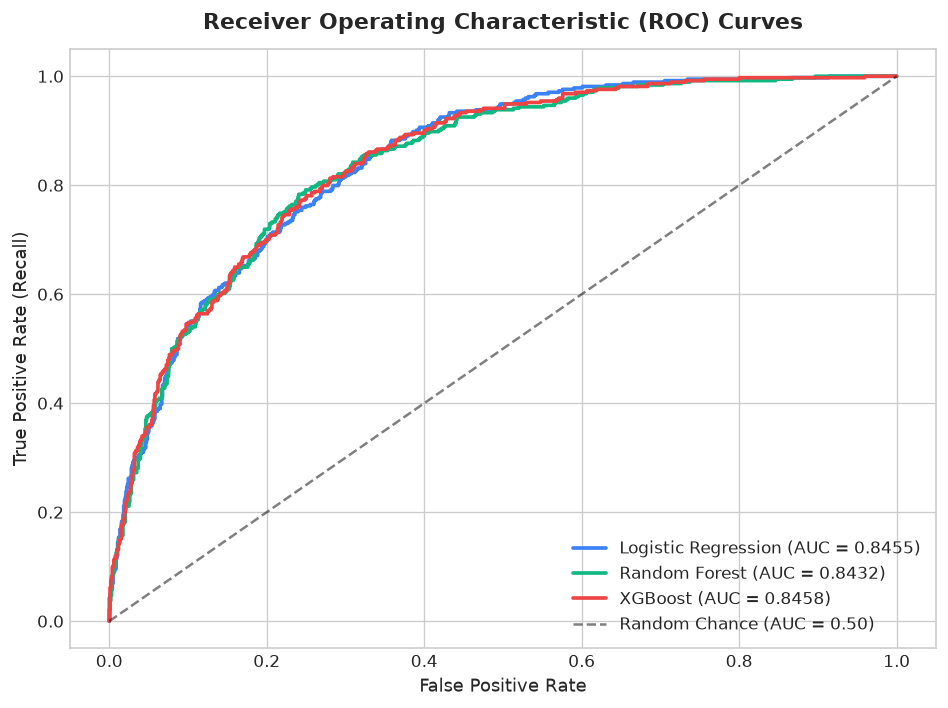

In [5]:
plt.figure(figsize=(8, 6))
colors = {'Logistic Regression': '#3b82f6', 'Random Forest': '#10b981', 'XGBoost': '#ef4444'}
for name in models.keys():
    fpr, tpr, _ = roc_curve(y_test, probs[name])
    auc = roc_auc_score(y_test, probs[name])
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.4f})", color=colors[name], linewidth=2.2)

plt.plot([0, 1], [0, 1], 'k--', alpha=0.5, label='Random Chance (AUC = 0.50)')
plt.title('Receiver Operating Characteristic (ROC) Curves', fontsize=13, weight='bold', pad=12)
plt.xlabel('False Positive Rate', fontsize=11)
plt.ylabel('True Positive Rate (Recall)', fontsize=11)
plt.legend(loc='lower right', fontsize=10)
plt.tight_layout()
plt.show()

## 6. Confusion Matrix Comparison

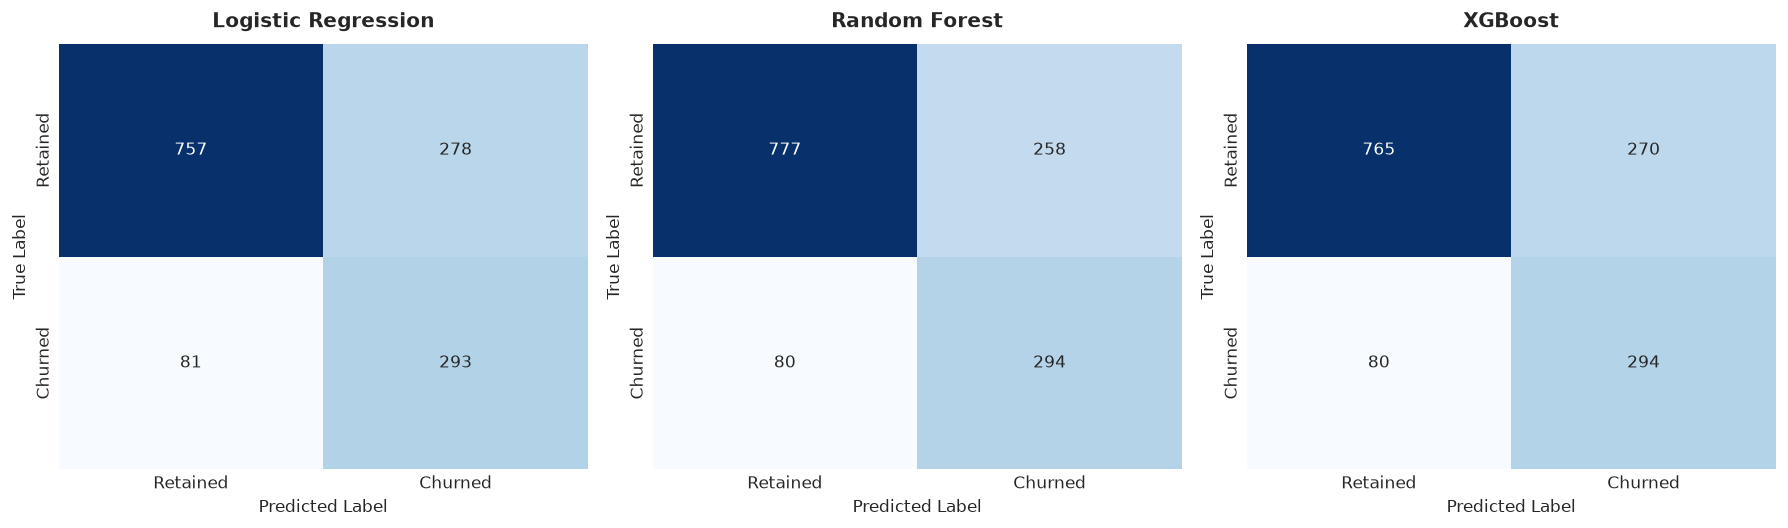

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for i, (name, y_pred) in enumerate(preds.items()):
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[i], cbar=False,
                xticklabels=['Retained', 'Churned'], yticklabels=['Retained', 'Churned'])
    axes[i].set_title(f"{name}", fontsize=12, weight='bold', pad=10)
    axes[i].set_xlabel('Predicted Label')
    axes[i].set_ylabel('True Label')

plt.tight_layout()
plt.show()

## 7. SHAP Explainability (TreeExplainer)
SHAP reveals the exact contribution of each feature to the model's prediction.

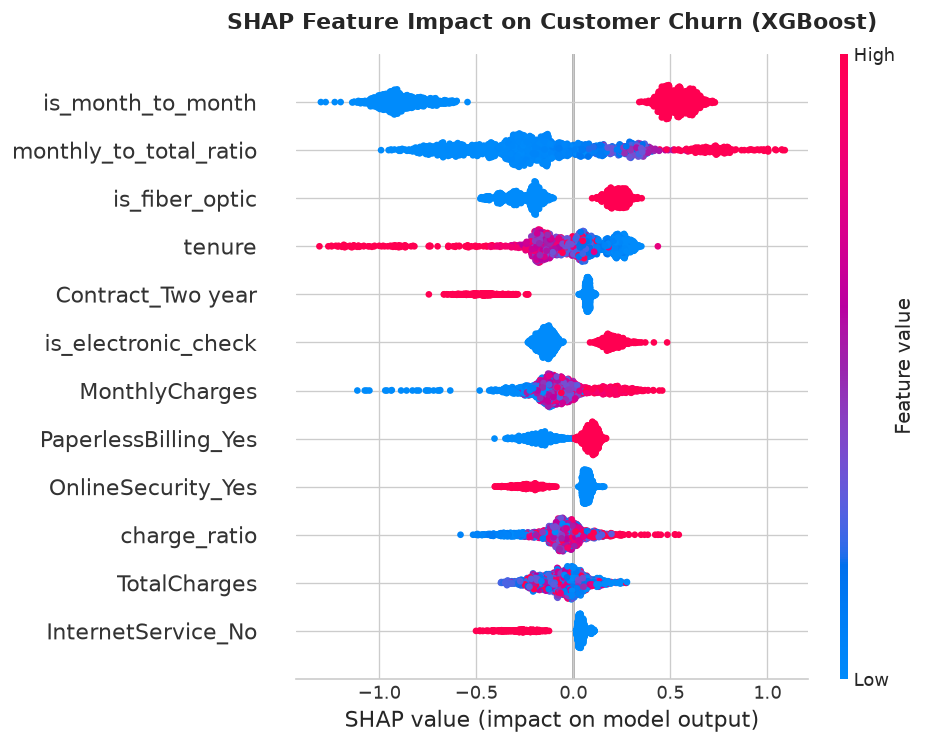

In [7]:
explainer = shap.TreeExplainer(fitted_models['XGBoost'])
shap_values = explainer(X_test.values)

# Summary Beeswarm Plot
plt.figure(figsize=(10, 7))
shap.summary_plot(shap_values.values, X_test, feature_names=feature_names, max_display=12, show=False)
plt.title('SHAP Feature Impact on Customer Churn (XGBoost)', fontsize=13, weight='bold', pad=15)
plt.tight_layout()
plt.show()

## 8. Summary of Findings & Production Deployment

- **Top Predictor:** `is_month_to_month` has the single highest positive SHAP impact on churn.
- **Retention Differentiators:** High tenure and two-year contract commitment are massive churn suppressors.
- **Production Decision:** **XGBoost** is designated as our primary engine (ROC-AUC: 0.8458, Recall: 78.61%).
- Pre-trained models are saved in `models/` directory for fast inference.